[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Rishabh-bgp/rso-net-wind-grid-stabilization/blob/main/notebooks/rso-net-wind-grid-stabilization_walkthrough.ipynb)

# Walkthrough: RSO-Net (dilated causal TCN + self-attention, point forecast = median)

A short, beginner-friendly tour of this repository.

> **Important:** this notebook uses a **synthetic** SCADA-style dataset made by a script. It is **not** the confidential SCADA data used in the paper. The model here is a deliberately tiny, briefly trained version, so the numbers below **do not reproduce the paper's results** and only show that the pipeline works. This is an independent reimplementation, not the authors' code.

## 1. Setup
If the notebook is opened on its own (for example in Colab), this cell downloads the repository code from GitHub and installs the libraries. Locally it does nothing extra.

In [1]:
import os, sys, subprocess
if not os.path.exists('src') and os.path.exists('../src'):
    os.chdir('..')                      # running from notebooks/ inside the repo
if not os.path.exists('src'):           # running alone (e.g. Colab): fetch the public repo
    if not os.path.exists('rso-net-wind-grid-stabilization'):
        subprocess.run(['git', 'clone', '--depth', '1', 'https://github.com/Rishabh-bgp/rso-net-wind-grid-stabilization.git'], check=True)
    os.chdir('rso-net-wind-grid-stabilization')
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', '-r', 'requirements.txt'], check=True)
sys.path.insert(0, os.getcwd())
print('working directory:', os.getcwd())

working directory: /workspace/wind-quantum/rso-net-wind-grid-stabilization


## 2. Load the synthetic data
We try, in order: the local file, the copy on GitHub, and finally the built-in generator (seed 0).

In [2]:
import pandas as pd
from src.data import synthetic_scada
LOCAL = 'data/synthetic/synthetic_scada.csv'
RAW = 'https://raw.githubusercontent.com/Rishabh-bgp/rso-net-wind-grid-stabilization/main/data/synthetic/synthetic_scada.csv'
try:
    df = pd.read_csv(LOCAL); source = 'local file'
except Exception:
    try:
        df = pd.read_csv(RAW); source = 'GitHub raw URL'
    except Exception:
        df = synthetic_scada(1500, seed=0); source = 'built-in generator (seed 0)'
df['timestamp'] = pd.to_datetime(df['timestamp'])
print('Loaded', len(df), 'rows from', source, '(SYNTHETIC data)')
df.head()

Loaded 3000 rows from local file (SYNTHETIC data)


,timestamp,active_power,wind_speed,theoretical_power,wind_direction
0,2018-01-01 00:00:00,281.977892,7.000000,268.727220,198.773312
1,2018-01-01 00:10:00,290.060315,7.153167,300.794548,198.578111
2,2018-01-01 00:20:00,268.974942,7.187313,308.274852,198.609009
3,2018-01-01 00:30:00,375.732170,7.571878,401.250558,196.710173
4,2018-01-01 00:40:00,475.690721,7.700536,436.087730,195.676690


## 3. Quick look at the data (EDA)
Wind speed over time, its distribution, and how power follows wind speed (the turbine power curve).

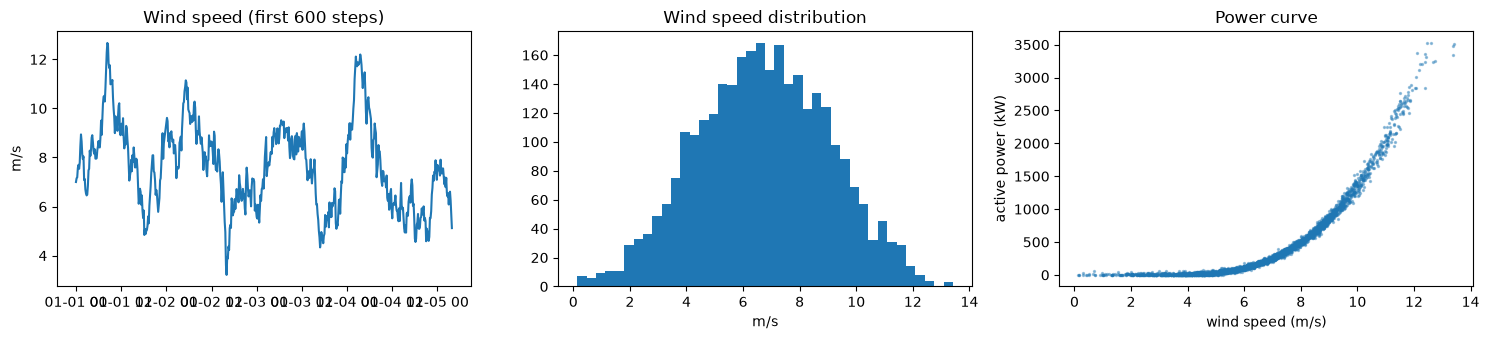

,timestamp,active_power,wind_speed,theoretical_power,wind_direction
count,3000,3000.00,3000.00,3000.00,3000.00
mean,2018-01-11 09:55:00,443.70,6.71,466.13,238.12
min,2018-01-01 00:00:00,0.00,0.13,0.00,0.01
25%,2018-01-06 04:57:30,39.40,5.09,38.28,211.75
50%,2018-01-11 09:55:00,201.65,6.70,213.51,277.99
75%,2018-01-16 14:52:30,624.47,8.41,664.45,320.93
max,2018-01-21 19:50:00,3526.28,13.42,3600.00,359.98
std,NaN,591.19,2.33,622.67,110.65


In [3]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(1, 3, figsize=(15, 3.5))
ax[0].plot(df['timestamp'][:600], df['wind_speed'][:600]); ax[0].set_title('Wind speed (first 600 steps)'); ax[0].set_ylabel('m/s')
ax[1].hist(df['wind_speed'], bins=40); ax[1].set_title('Wind speed distribution'); ax[1].set_xlabel('m/s')
ax[2].scatter(df['wind_speed'], df['active_power'], s=2, alpha=0.4); ax[2].set_title('Power curve'); ax[2].set_xlabel('wind speed (m/s)'); ax[2].set_ylabel('active power (kW)')
plt.tight_layout(); plt.show()
df.describe().round(2)

## 4. Turn the series into training windows
Each sample is the last 24 time steps (wind speed, direction as sin/cos, theoretical and active power).

**Trick: predict the change, not the level.** Wind speed barely moves in 10 minutes, so instead of predicting the next speed directly we predict the *change* from the current speed (the delta) and add it back afterwards. A model that learns nothing then falls back to persistence instead of doing worse, and anything it does learn is an improvement on top.

The data is split in time order: 70% train, 15% validation, 15% test, all normalised with training statistics.

In [4]:
import numpy as np, torch
from src.data import make_windows, split_scale
torch.manual_seed(0); np.random.seed(0)
LOOKBACK = 24
X, Y = make_windows(df, lookback=LOOKBACK, horizon=1)
last = X[:, -1, 0]            # current wind speed (raw m/s) at the end of each window
tr, va, te, scale = split_scale(X, Y - last)   # target = delta
N_TRAIN = 800  # only the most recent training windows, to keep the demo fast
tr = (tr[0][-N_TRAIN:], tr[1][-N_TRAIN:])
n_test = len(te[0]); last_test = last[-n_test:]; y_test = Y[-n_test:]
print('train', tr[0].shape, 'val', va[0].shape, 'test', te[0].shape)

train (800, 24, 5) val (446, 24, 5) test (447, 24, 5)


## 5. Build a small version of the model
We use the repository's own model code, with smaller settings so it runs quickly on a CPU. This model is fully classical.

In [5]:
from src.rso_net import RSONet
model = RSONet(n_feat=5, ch=16, dilations=(1, 2, 4), heads=2)
print(sum(p.numel() for p in model.parameters()), 'trainable parameters')

2963 trainable parameters


## 6. Train briefly

In [6]:
from src.train_common import fit
# For simplicity we train the median (P50) output with MSE here; train.py uses the full quantile (pinball) loss.
fit(model, tr, va, epochs=15, lr=3e-3)

epoch 1/15 val_mse=1.0454


epoch 2/15 val_mse=0.9645


epoch 3/15 val_mse=0.9530


epoch 4/15 val_mse=0.9601


epoch 5/15 val_mse=0.9565


...

epoch 12/15 val_mse=0.9526


epoch 13/15 val_mse=0.9554


epoch 14/15 val_mse=0.9539


epoch 15/15 val_mse=0.9531


0.9520251154899597

## 7. Compare with a persistence baseline
**In plain words:** *persistence* just says "the next reading will be the same as the current one". Ten minutes ahead, that is already very accurate, so it is the honest yardstick: a forecasting model is only useful if it gets close to or beats it. A model that loses to persistence has not learned anything useful yet.

This is a **short demo on synthetic data** with a tiny model and a few epochs, so whichever way the comparison goes, it says nothing about the method's accuracy on real wind-farm data or about the paper's results.

In [7]:
from src.metrics import regression_metrics
model.eval()
with torch.no_grad():
    pred = last_test + model(torch.tensor(te[0])).numpy() * scale[1] + scale[0]   # add the delta back
y = y_test
res = pd.DataFrame({'model (tiny, brief training)': regression_metrics(y, pred),
                    'persistence baseline': regression_metrics(y[1:], y[:-1])}).round(3)
res

,"model (tiny, brief training)",persistence baseline
MAE,0.361,0.362
RMSE,0.446,0.449
MAPE_%,7.701,7.652
R2,0.935,0.935


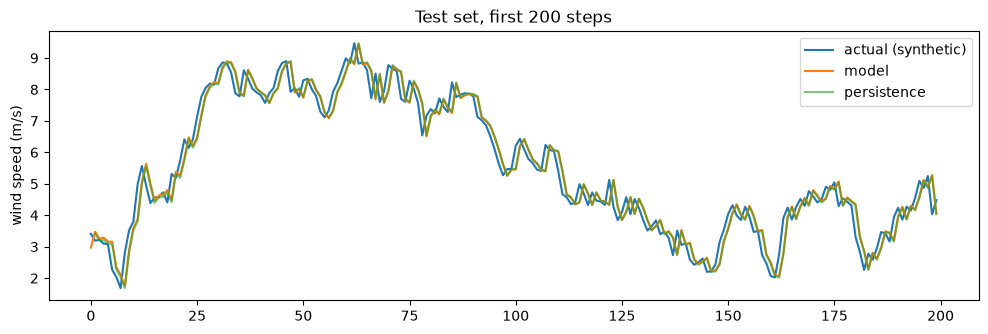

In [8]:
plt.figure(figsize=(12, 3.5))
plt.plot(y[:200], label='actual (synthetic)'); plt.plot(pred[:200], label='model'); plt.plot(np.r_[np.nan, y[:199]], label='persistence', alpha=0.6)
plt.ylabel('wind speed (m/s)'); plt.title('Test set, first 200 steps'); plt.legend(); plt.show()

## 8. Takeaways
- The whole pipeline (load, window, model, train, evaluate) runs end to end.
- These numbers come from **synthetic data** and a **tiny, briefly trained model**, so they say nothing about the method's real accuracy and **do not reproduce the paper**.
- For a full run use `python train.py` (see the README), or pass your own SCADA-style CSV with `--csv path/to/file.csv`.